# Rutas Condiciones en LangGraph
Ahora vamos a conseguir que LangGraph tome caminos diferentes según el resultado de una comprobación.

Queremos algo más inteligente:
- Si la CPU es inferior o igual al 90 %, finalizar.
- Si la CPU supera el 90 %, ejecutar una comprobación adicional de procesos.
- Después, generar un diagnóstico.

## Conditional Edge.
Una arista condicional permite seleccionar el siguiente nodo según una función Python que evalúa el estado.

## Resumen de la clase 2

| Concepto | Función |
|---|---|
| `add_conditional_edges()` | Añade rutas condicionales al grafo. |
| Router | Función que evalúa el estado y devuelve la ruta. |
| `Literal` | Anotación de tipos que permite declarar los posibles resultados de la función. |

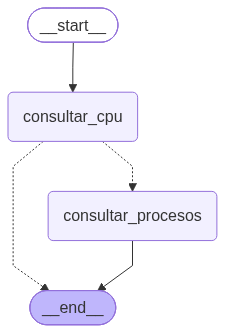

Consultando CPU de srv-oracle-01
CPU elevada. Consultando procesos...
Consultando procesos Linux...

RESULTADO FINAL:
{'servidor': 'srv-oracle-01', 'cpu': 95, 'proceso': 'oracle', 'diagnostico': 'CPU elevada. Proceso oracle detectado.'}


In [1]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


# 1. STATE
class AgentState(TypedDict):
    servidor: str
    cpu: int
    proceso: str
    diagnostico: str


# 2. NODE: Consultar CPU
def consultar_cpu(state: AgentState):
    print(f"Consultando CPU de {state['servidor']}")

    # CPU simulada para practicar
    return {"cpu": 95}


# 3. ROUTER: Decidir el siguiente paso
def decidir_ruta(state: AgentState) -> Literal[
    "consultar_procesos", "__end__"
]:
    if state["cpu"] > 90:
        print("CPU elevada. Consultando procesos...")
        return "consultar_procesos"

    print("CPU normal. Finalizando.")
    return "__end__"


# 4. NODE: Consultar procesos
def consultar_procesos(state: AgentState):
    print("Consultando procesos Linux...")

    # Proceso simulado
    return {
        "proceso": "oracle",
        "diagnostico": "CPU elevada. Proceso oracle detectado."
    }


# 5. CREAR EL GRAFO
builder = StateGraph(AgentState)

builder.add_node("consultar_cpu", consultar_cpu)
builder.add_node("consultar_procesos", consultar_procesos)


# 6. DEFINIR CONEXIONES
builder.add_edge(START, "consultar_cpu")

builder.add_conditional_edges(
    "consultar_cpu",
    decidir_ruta,
    {
        "consultar_procesos": "consultar_procesos",
        "__end__": END
    }
)

builder.add_edge("consultar_procesos", END)


# 7. COMPILAR
graph = builder.compile()


# 8. VISUALIZAR EL GRAFO EN JUPYTER
display(Image(graph.get_graph().draw_mermaid_png()))


# 9. EJECUTAR
resultado = graph.invoke({
    "servidor": "srv-oracle-01",
    "cpu": 0,
    "proceso": "",
    "diagnostico": "CPU dentro de límites normales"
})

print("\nRESULTADO FINAL:")
print(resultado)